# Fit the full microscope from Gaussian images

TemGym generates images by summing **complex Gaussian fields**, including interference. We measure those images, then fit a separate microscope through its transfer matrices. The fitter starts from guesses and does not receive the generating lens or source parameters.

In [1]:
from pathlib import Path
import sys
import jax

%matplotlib inline

jax.config.update("jax_enable_x64", True)

here = Path.cwd()
model_directory = here if (here / "full_microscope_workflow.py").exists() else here / "examples/microscope_models"
sys.path.insert(0, str(model_directory))

from full_microscope_workflow import (
    simulate_experiment, show_images,
    measure_projector, fit_projector,
    measure_condenser, fit_microscope,
    check_full_microscope,
)
from full_microscope_checks import show_result

experiment_directory = model_directory.parent / "generated/full_microscope_gaussian_pipeline"
projector_bounds = model_directory / "projector_position_priors.json"
print("JAX device:", jax.devices()[0])

JAX device: cuda:0


The experiment uses **200 and 195 kV**, with objective current fixed. It records lens sweeps, calibrated specimen tilts and shifts, and currents through centred **4 and 10 µm apertures**. Apertures are retracted for imaging.

For this synthetic test, the specimen's amplitude and phase transmission and the detector response are known. We fit lens positions, lengths and strengths, separate source states at each voltage, and aperture position and centres. The lens model is coaxial.

The projector calibration assumes a known circular illumination profile, with unknown curvature and angular spread.

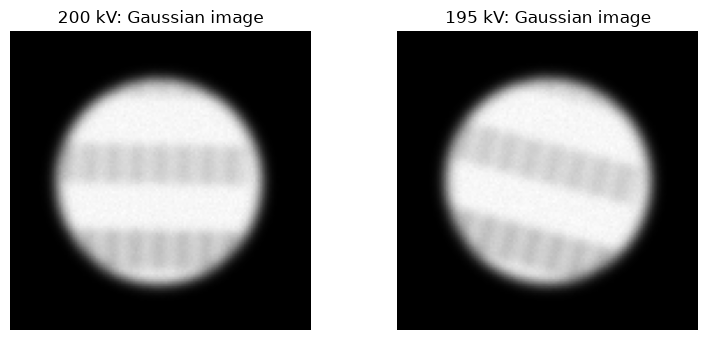

In [2]:
# Supply acquisition settings. Output: saved images, currents and known commands.
experiment = simulate_experiment(
    output_directory=experiment_directory,
    voltages_v=(200_000., 195_000.),
    aperture_diameters_um=(4., 10.),
    centering_sigma_um=0.2,
    image_model="coherent_gaussian",
    reuse_completed=True,
)
show_images(experiment_directory=experiment);

The ray order is $(x,y,\theta_x,\theta_y,1)^T$. TemGym builds

$$
T=\begin{pmatrix}
A_{xx}&A_{xy}&B_{xx}&B_{xy}&t_x\\
A_{yx}&A_{yy}&B_{yx}&B_{yy}&t_y\\
C_{xx}&C_{xy}&D_{xx}&D_{xy}&\eta_x\\
C_{yx}&C_{yy}&D_{yx}&D_{yy}&\eta_y\\
0&0&0&0&1
\end{pmatrix}.
$$

The shared lens positions, lengths and strengths determine these entries. Known tilts probe $B$; image changes and known shifts constrain the remaining parameters.

**First fit the projector.** Measure image centroids and shapes, with their uncertainties. The matrix model predicts these same quantities. With $R=(A\;B)$, exit-wave mean $m$ and covariance $S$,

$$m_d=Rm+t,\qquad S_d=RSR^T+S_{\mathrm{detector}}.$$

The predictor includes the known specimen's phase, diffraction and finite detector pixels. JAX differentiates these measurements with respect to lens parameters; it does not render pixels during fitting.

In [3]:
# Supply recorded projector images. Output: image measurements and covariance.
projector_measurements = measure_projector(experiment_directory=experiment)

# Supply measurements, independent guesses and engineering bounds.
# Output: shared projector geometry, uncertainty and results from four starts.
projector = fit_projector(
    measurements_directory=projector_measurements,
    starting_guess_path=model_directory / "projector_starting_guess.json",
    bounds_path=projector_bounds,
    number_of_starts=4,
)

**Then measure the condenser beam.** Three projector views estimate its position, angle, size, curvature and angular spread at each condenser setting. This step includes the fitted projector's uncertainty and corrects for finite detector pixels.

In [4]:
# Supply condenser images and the calibrated projector.
# Output: independent specimen-beam measurements, with shared uncertainty.
beam_measurements = measure_condenser(
    experiment_directory=experiment,
    projector_fit=projector,
    projector_bounds_path=projector_bounds,
)

**Fit the complete microscope.** Beam estimates initialize the condenser fit. A final joint fit compares the original image measurements and aperture currents with both fitted halves, retaining their shared uncertainty.

We fit CL1, CL3, the mini lens, objective pre-field, sources and aperture geometry. The constraints are engineering bounds and the stated aperture-centering accuracy. The fitter also checks for alternative aperture centres.

In [5]:
# Supply the saved image/beam/current measurements and separate condenser starting guesses.
# Output: both fitted halves and their joint covariance.
microscope = fit_microscope(
    beam_measurements_directory=beam_measurements,
    condenser_starting_guess_path=model_directory / "microscope_condenser_starting_guess.json",
    projector_bounds_path=projector_bounds,
    number_of_broad_starts=4,
)

**Check the recovered model.** Freeze its geometry and generate Gaussian predictions for new settings. Only after comparing measurements do we open the generating parameters to score the geometry errors.

| Lens | True z (mm) | Fitted z ± 1σ (mm) | True length (mm) | Fitted length ± 1σ (mm) |
|---|---:|---:|---:|---:|
| CL1 | -125 | -125.008 ± 0.036 | 5 | 4.99901 ± 0.014 |
| CL3 | -85 | -85.0055 ± 0.044 | 5 | 5.0007 ± 0.0011 |
| Mini | -25 | -25.002 ± 0.021 | 3 | 3.00018 ± 0.0036 |
| Objective pre-field | -2.5 | -2.49965 ± 0.0008 | 1 | 0.995968 ± 0.042 |
| Objective post-field | 2.3 | 2.29992 ± 0.0003 | 0.4 | 0.399711 ± 0.00017 |
| IL1 | 213.52 | 213.516 ± 0.029 | 5 | 4.99958 ± 0.00089 |
| IL2 | 290.48 | 290.471 ± 0.039 | 5 | 4.9999 ± 0.00071 |
| IL3 | 352.98 | 352.97 ± 0.047 | 5 | 4.99972 ± 0.00078 |
| PL1 | 407.98 | 407.973 ± 0.055 | 1 | 1.00002 ± 0.00014 |

| Prediction check | RMS in noise units |
|---|---:|
| New images (beam region) | 0.982 |
| New aperture currents | 1.199 |
| New projector settings | 0.888 |

Quantity,Truth,Fit ± 1σ,Range across acceptable starts
detector z mm,718.75,718.739 ± 0.095,—
condenser source z mm,-325,-325.025 ± 0.4,-325.025 to -325.015
condenser aperture z mm,-80,-80.0053 ± 0.044,-80.0053 to -80.0048
condenser aperture x um,0.215898,0.228723 ± 0.052,0.2114 to 0.228723
condenser aperture y um,-0.503777,-0.499125 ± 0.024,-0.506711 to -0.499125
condenser source z second voltage mm,-325.05,-325.075 ± 0.4,-325.075 to -325.065
condenser aperture 2 x um,0.155747,0.163705 ± 0.0082,-0.0979599 to 0.163705
condenser aperture 2 y um,-0.0409891,-0.0295223 ± 0.016,-0.128504 to -0.0295223


**Some aperture-centre coordinates have several acceptable values.** Their local error bars describe only the selected minimum; inspect the range across starts above.

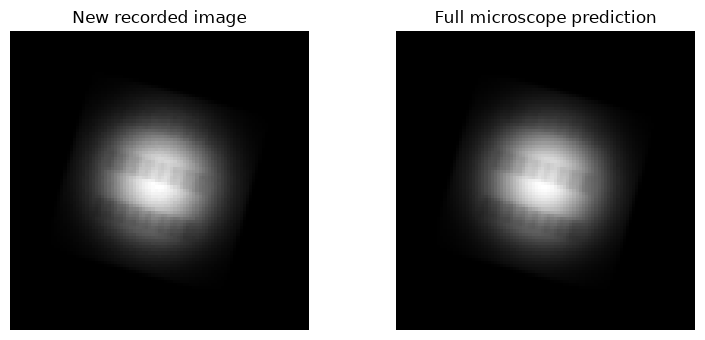

In [6]:
checks = check_full_microscope(
    experiment_directory=experiment,
    microscope=microscope,
    projector_bounds_path=projector_bounds,
)
show_result(checks=checks)
show_images(experiment_directory=experiment, fitted_predictions=True);

The error bars describe local uncertainty within this model. Agreement between starts and new-image predictions supports the recovered solution; it does not prove global uniqueness or validate a real microscope's field profile.

Saved stages are reused when their inputs match. Image generation, numerical refinement and fitting logs remain beside the recorded data.